In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import datetime 
import utils

# Analysing dataset

In [2]:
start_date=datetime.date.fromisoformat('2025-08-15')
end_date=datetime.date.fromisoformat('2025-09-16')
input_dir='data/Old daily positions/'

In [3]:
str(start_date)

'2025-08-15'

## Checking the sampling frequency

In [12]:
date=start_date
dfs=[]
while date<end_date:
    fname=input_dir+'day_positions('+str(date)+').pkl'
    try:
        day_positions=pd.read_pickle(fname)

        day_positions=day_positions.sort_values('timestamp')
        daytimes=day_positions.drop_duplicates('timestamp')
        dfs.append(daytimes)
        print(date)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
times=pd.concat(dfs)
times=times.drop_duplicates('timestamp').reset_index(drop=True)

2025-08-15
2025-08-16 not found
2025-08-17 not found
2025-08-18 not found
2025-08-19 not found
2025-08-20 not found
2025-08-21
2025-08-22
2025-08-23
2025-08-24
2025-08-25
2025-08-26
2025-08-27
2025-08-28
2025-08-29
2025-08-30
2025-08-31
2025-09-01
2025-09-02
2025-09-03
2025-09-04


KeyboardInterrupt: 

In [6]:
times=times.drop_duplicates('timestamp').sort_values('timestamp').reset_index(drop=True)
deltas=times.loc[1:,'timestamp'].reset_index(drop=True)-times.loc[0:day_positions.shape[0]-1,'timestamp']
times['deltas']=deltas
print(deltas.describe())

count    106230.000000
mean         25.845666
std        1516.539860
min          20.142499
25%          20.201121
50%          20.232756
75%          20.295366
max      493916.496959
Name: timestamp, dtype: float64


In [39]:
min_time=pd.Timestamp(times.index.min(), unit='s')#Timestamp('2025-08-15 05:20:13.152456045')
max_time=pd.Timestamp(times.index.max(), unit='s')#Timestamp('2025-09-15 23:59:58.297766924')
(max_time-min_time).total_seconds()/20

137279.2572655

In [43]:
times['geometry'].count()/((max_time-min_time).total_seconds()/20)

np.float64(0.7738314011602478)

In [19]:
deltas.quantile(0.96978)

np.float64(20.99999920185566)

In [20]:
deltas.sort_values().reset_index(drop=True).tail(30)

106201        49.522749
106202        49.803055
106203        50.241682
106204        53.004385
106205        60.800557
106206        70.940983
106207       122.226628
106208       262.612649
106209       708.984506
106210      1616.832924
106211      1759.711319
106212      2816.771676
106213      2879.044083
106214      3221.005183
106215      3226.422848
106216      4296.274997
106217      4357.196986
106218      4942.941263
106219      4963.247134
106220      4983.799194
106221      4984.321924
106222      4994.951633
106223      5245.354416
106224      5245.487668
106225      5247.687330
106226      5273.662014
106227      5284.371371
106228      6749.276014
106229    493916.496959
106230              NaN
Name: timestamp, dtype: float64

KeyError: 'timestamp'

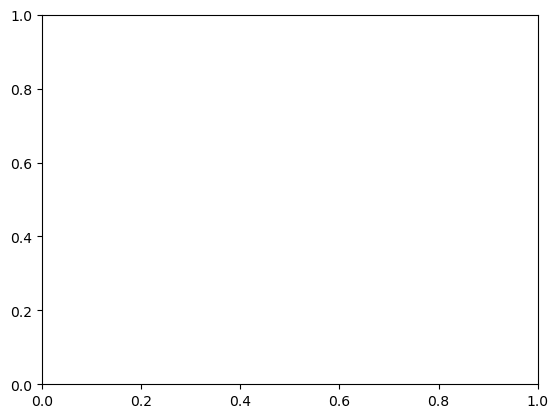

In [44]:
times.plot.scatter(x='timestamp',y='deltas',ylim=(0,7000))

In [ ]:
times.plot.scatter(x='timestamp',y='deltas',ylim=(0,60))

In [ ]:
deltas.plot.hist(ylim=(0.97,1),xlim=(20,60),range=(20,10000),bins=9980, cumulative=True, density=True, grid=True)

In [ ]:
deltas.plot.hist(ylim=(75000,78000),xlim=(20,10000),range=(20,100000),bins=1000, cumulative=True, grid=True)

In [ ]:
deltas.plot.hist(log=True, range=(18,8000),bins=42)

## ???

In [ ]:
all_positions.duplicated(['pointId','timestamp']).value_counts()

## Décalage temporel ?

In [72]:
import utils
sdate='2025-09-06'
date=datetime.datetime.fromisoformat(sdate)

data_dir="data"

In [35]:
GTFS_zip_files=['GTFS_2025-08-13T04-20-01.zip', 'GTFS_2025-08-22T04-20-01.zip',
                'GTFS_2025-09-03T04-20-01.zip','GTFS_2025-09-04T04-20-01.zip','GTFS_2025-09-15T04-20-01.zip']
GTFS_dates=['2025-08-13','2025-08-22','2025-09-03','2025-09-04','2025-09-15']

active_GTFS_zip_file = None
for i in range(1, len(GTFS_dates)):
    if GTFS_dates[i] > sdate:
        active_GTFS_zip_file = GTFS_zip_files[i-1]
        break
if active_GTFS_zip_file is None: active_GTFS_zip_file = GTFS_zip_files[-1]

geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
active_stop_times, active_trips =utils.get_active_stop_times(sdate, trips, stop_times, calendar, calendar_dates)
active_stop_times=active_stop_times.assign(arrival_datetime=active_stop_times['arrival_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))),
                             departure_datetime=active_stop_times['departure_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))))
#%% Fusionne les stop_times actifs et les routes
act=active_trips[['route_id', 'trip_id', 'direction_id', 'shape_id']].merge(active_stop_times, on='trip_id', how='outer')
r=routes[['route_id', 'route_short_name','route_type']]
r.assign(route_short_name=r['route_short_name'].astype('string'))
act=act.merge(r, on='route_id', how='outer', indicator=True)
print("Résultat de la fusion entre les stop_times actifs(horaire du jour) et les routes(lignes)")
print(act.drop_duplicates('route_id')['_merge'].value_counts())
s=act.query("_merge=='right_only'")
act=act[act['_merge']!="right_only"]
act=act.drop('_merge',axis=1)

Feed infos: GTFS_2025-09-04T04-20-01.zip
Version: 2_20_20250903_010546
From 2025-09-01 00:00:00 to 2025-09-28 00:00:00
Files read              


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


Résultat de la fusion entre les stop_times actifs(horaire du jour) et les routes(lignes)
_merge
both          83
right_only     6
left_only      0
Name: count, dtype: int64


Avec les anciens fichiers

In [18]:
fname='day_positions('+str(date)+').pkl'
try:
    day_positions=pd.read_pickle(input_dir+fname)

    day_positions=day_positions.sort_values('timestamp')
except FileNotFoundError:
    print(date,'not found')
day_positions['datetime']=pd.to_datetime(day_positions['timestamp'], unit='s')

In [19]:
day_positions.columns

Index(['geometry', 'id', 'pointId', 'lineId', 'direction', 'distanceFromPoint',
       'timestamp', 'uuid', 'distance'],
      dtype='object')

In [62]:
day_positions['datetime'].dt.date.iloc[0]

datetime.date(2025, 9, 5)

2025-09-06 03:40:40.483479977
2025-09-06 22:45:06.072546959


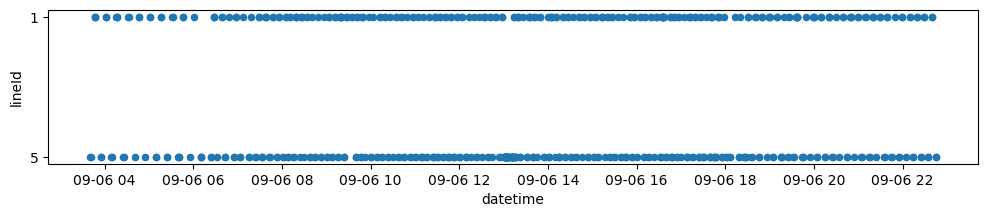

In [69]:
day_positions['date']=day_positions['datetime'].dt.date
day_positions.query("(distanceFromPoint<1)&(pointId==8032)&(date==@date.date())").sort_values('datetime').plot.scatter(x='datetime', y='lineId', figsize=(12,2))
print(day_positions.query("(distanceFromPoint<1)&(pointId==8032)&(date==@date.date())")['datetime'].min())
print(day_positions.query("(distanceFromPoint<1)&(pointId==8032)&(date==@date.date())")['datetime'].max())

2025-09-06 05:40:46
2025-09-07 00:44:33


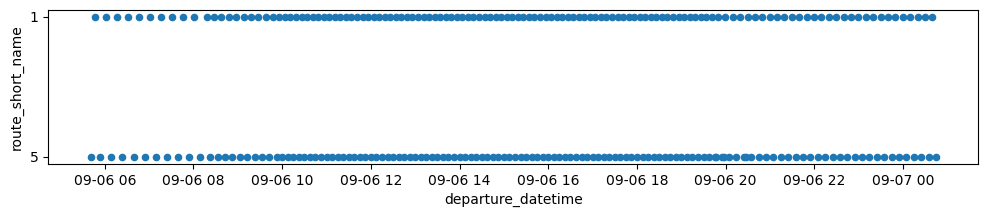

In [70]:
act.query("(stop_id=='8032')").sort_values('departure_datetime').plot.scatter(x='departure_datetime', y='route_short_name', figsize=(12,2))
print(act.query("(stop_id=='8032')")['departure_datetime'].min())
print(act.query("(stop_id=='8032')")['departure_datetime'].max())

On voit clairement que l'arrêt commence à être desservi à 5h40 dans le GTFS mais le premier véhicule à en partir dans VehiclePositions le fait à 3h40.
Donc, le temps dans VehiclePositions semble en avance de 2 heure

Avec les nouveaux fichiers:

In [93]:
input_dir='data/daily positions/'
fname='day_positions('+str(date.date())+').pkl'
try:
    day_positions=pd.read_pickle(input_dir+fname)

    day_positions=day_positions.sort_values('timestamp')
except FileNotFoundError:
    print(date,'not found')

In [94]:
day_positions['timestamp_dt'].max()

Timestamp('2025-09-07 03:59:58.400051117+0200', tz='UTC+02:00')

In [95]:
day_positions['date']=day_positions['timestamp_dt'].dt.date

8032
2025-09-06 00:00:01.027543068+02:00 to 2025-09-07 00:45:06.072546959+02:00
2025-09-06 05:40:46 to 2025-09-07 00:44:33


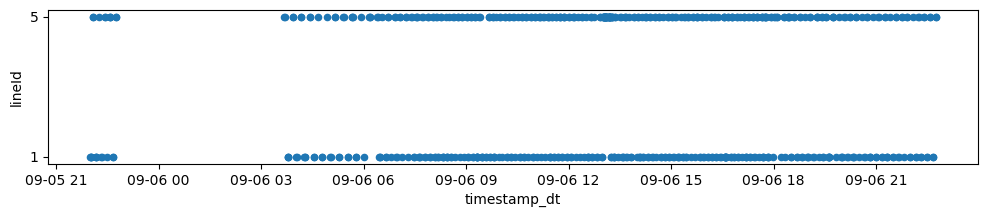

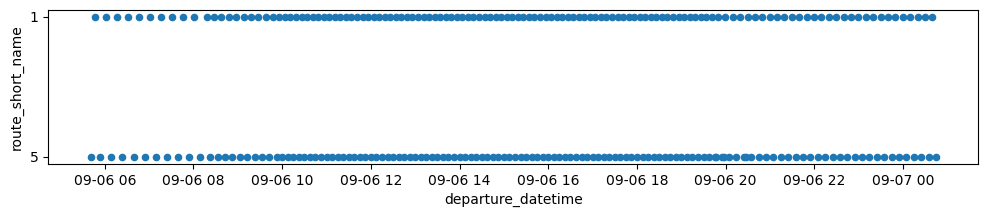

In [96]:
s=day_positions.sample(1)
sample_point=8032#s['pointId'].iloc[0]
print(sample_point)
sample=day_positions.query("(distanceFromPoint<1)&(pointId==@sample_point)")#&(date==@date.date())").sort_values('datetime')
sample.plot.scatter(x='timestamp_dt', y='lineId', figsize=(12,2))
print(sample['timestamp_dt'].min(),'to',sample['timestamp_dt'].max())
sample_point=str(sample_point)
sample_GTFS=act.query("(stop_id==@sample_point)").sort_values('departure_datetime')
sample_GTFS.plot.scatter(x='departure_datetime', y='route_short_name', figsize=(12,2))
print(sample_GTFS['departure_datetime'].min(),'to',sample_GTFS['departure_datetime'].max())

## Évolution du nombre de lignes

In [17]:
input_dir='data/daily positions/'
date=start_date
dfs=[]
uniques=[]
uniques_per_day=[]
while date<end_date:
    fname='day_positions('+str(date)+').pkl'
    try:
        day_positions=pd.read_pickle(input_dir+fname)

        day_positions=day_positions.sort_values('timestamp')
        counts=day_positions.groupby('timestamp_dt', as_index=False).count()
        unique=day_positions.groupby('timestamp_dt', as_index=False).nunique()
        day_positions['date']=day_positions['timestamp_dt'].dt.date
        unique_per_day=day_positions.groupby('date', as_index=False).nunique()
        dfs.append(counts)
        uniques.append(unique)
        uniques_per_day.append(unique_per_day)
        print(date)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_counts=pd.concat(dfs)
all_uniques=pd.concat(uniques)
all_uniques_day=pd.concat(uniques_per_day)
all_uniques=all_uniques.drop_duplicates('timestamp_dt').reset_index(drop=True)
all_counts=all_counts.drop_duplicates('timestamp_dt').reset_index(drop=True)

2025-08-15
2025-08-16 not found
2025-08-17 not found
2025-08-18 not found
2025-08-19 not found
2025-08-20 not found
2025-08-21
2025-08-22
2025-08-23
2025-08-24
2025-08-25
2025-08-26
2025-08-27
2025-08-28
2025-08-29
2025-08-30
2025-08-31
2025-09-01
2025-09-02
2025-09-03
2025-09-04
2025-09-05
2025-09-06
2025-09-07
2025-09-08
2025-09-09
2025-09-10
2025-09-11
2025-09-12
2025-09-13
2025-09-14
2025-09-15


In [11]:
all_counts

,timestamp_dt,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,uuid,distance
0,2025-08-15 07:20:13.152456045+02:00,197,197,197,197,197,197,197,197,197
1,2025-08-15 07:20:33.641208887+02:00,199,199,199,199,199,199,199,199,199
2,2025-08-15 07:20:53.867563963+02:00,197,197,197,197,197,197,197,197,197
3,2025-08-15 07:21:14.085609913+02:00,197,197,197,197,197,197,197,197,197
4,2025-08-15 07:21:34.304517031+02:00,194,194,194,194,194,194,194,194,194
...,...,...,...,...,...,...,...,...,...,...
106257,2025-09-16 01:58:37.534430027+02:00,1,1,1,1,1,1,1,1,1
106258,2025-09-16 01:58:57.751841068+02:00,1,1,1,1,1,1,1,1,1
106259,2025-09-16 01:59:17.946391106+02:00,1,1,1,1,1,1,1,1,1
106260,2025-09-16 01:59:38.111557007+02:00,1,1,1,1,1,1,1,1,1


In [22]:
all_uniques

,timestamp_dt,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,uuid,distance
0,2025-08-15 07:20:13.152456045+02:00,193,197,190,63,2,91,1,197,164
1,2025-08-15 07:20:33.641208887+02:00,197,199,191,63,2,93,1,199,167
2,2025-08-15 07:20:53.867563963+02:00,195,197,190,63,2,92,1,197,165
3,2025-08-15 07:21:14.085609913+02:00,195,197,192,63,2,99,1,197,164
4,2025-08-15 07:21:34.304517031+02:00,192,194,188,64,2,92,1,194,162
...,...,...,...,...,...,...,...,...,...,...
106257,2025-09-16 01:58:37.534430027+02:00,1,1,1,1,1,1,1,1,1
106258,2025-09-16 01:58:57.751841068+02:00,1,1,1,1,1,1,1,1,1
106259,2025-09-16 01:59:17.946391106+02:00,1,1,1,1,1,1,1,1,1
106260,2025-09-16 01:59:38.111557007+02:00,1,1,1,1,1,1,1,1,1


In [18]:
all_uniques_day

,date,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,uuid,distance,timestamp_dt
0,2025-08-15,2097,380,1840,65,2,2344,1448,6400,3808,1448
0,2025-08-21,2150,562,1878,69,2,3109,2700,15329,4531,2700
1,2025-08-22,1856,287,1662,64,2,904,449,676,2660,449
0,2025-08-22,2149,561,1880,69,2,3285,3981,18631,4588,3981
1,2025-08-23,1962,298,1721,70,2,953,707,765,2890,707
0,2025-08-23,2230,414,1915,71,2,3148,4239,15135,4504,4239
1,2025-08-24,1879,294,1681,64,2,934,550,683,2677,550
0,2025-08-24,2102,380,1842,65,2,3126,4083,14590,4252,4083
1,2025-08-25,1834,298,1649,64,2,924,449,653,2586,449
0,2025-08-25,2167,669,1899,69,2,3381,3894,20381,4642,3894


<Axes: xlabel='timestamp_dt'>

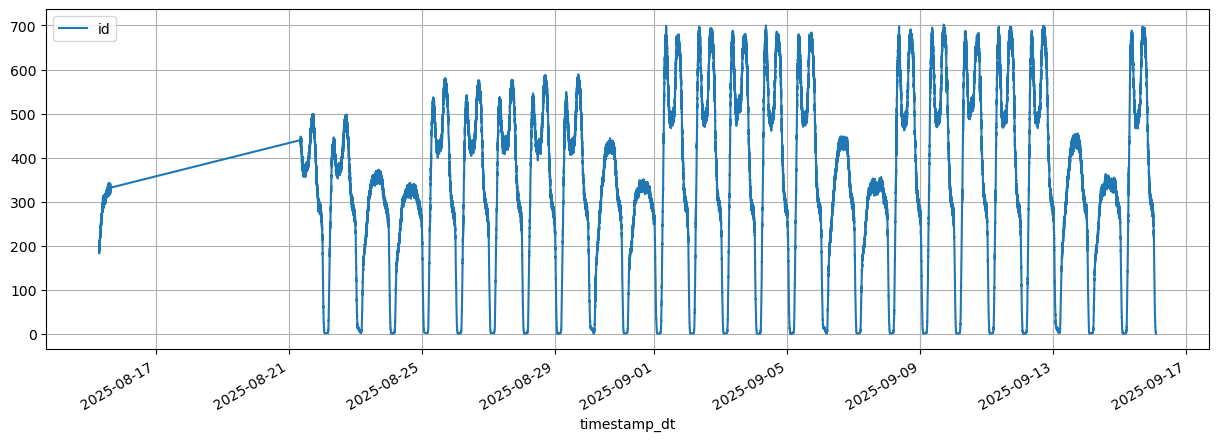

In [12]:
all_counts.plot(x='timestamp_dt',figsize=(15, 5), y='id', grid=True)

<Axes: title={'center': 'Number of rows per day'}, xlabel='timestamp_dt'>

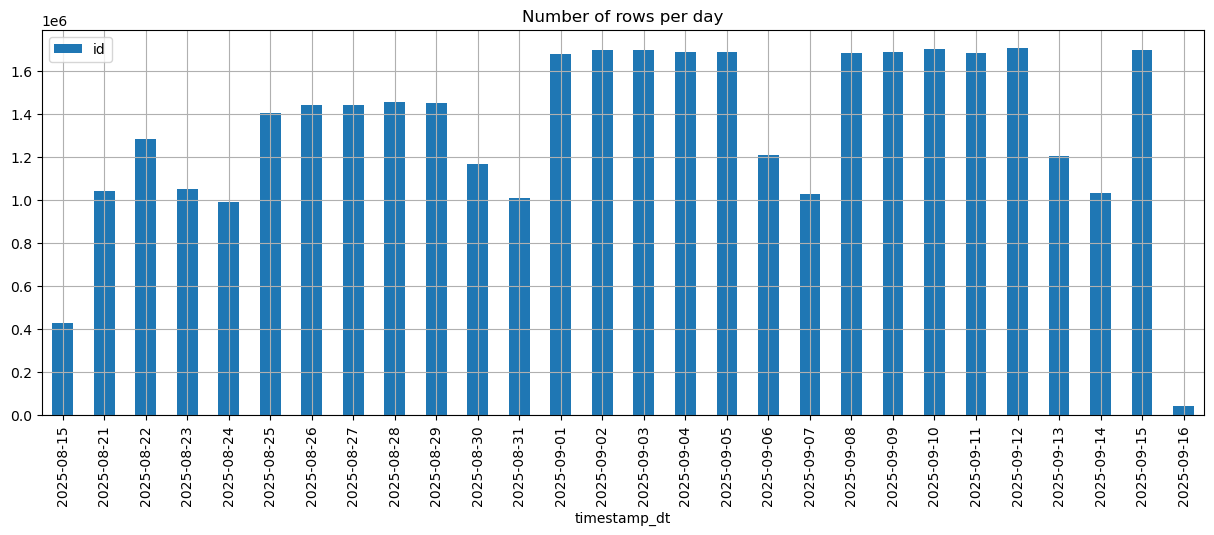

In [16]:
all_counts.groupby(all_counts["timestamp_dt"].dt.date).agg({'id':'sum'}).plot.bar(figsize=(15, 5), y='id', title='Number of rows per day', grid=True)

<Axes: title={'center': 'Number of vehicles per day'}>

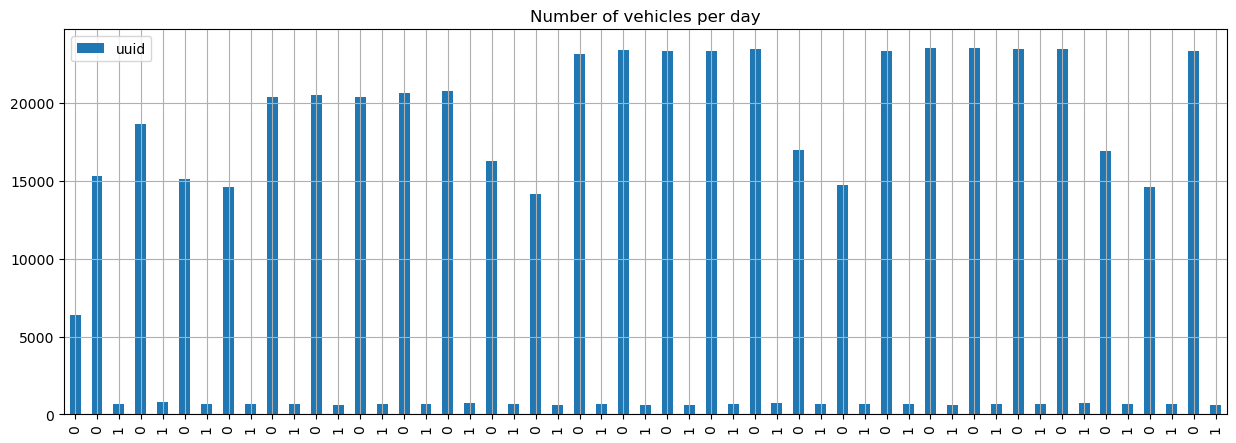

In [20]:
all_uniques_day.plot.bar(figsize=(15, 5), y='uuid', title='Number of vehicles per day', grid=True)

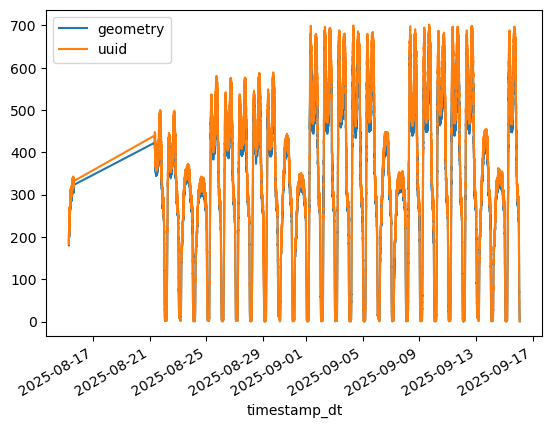

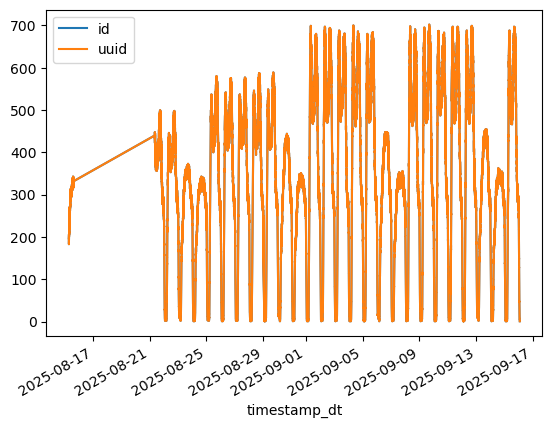

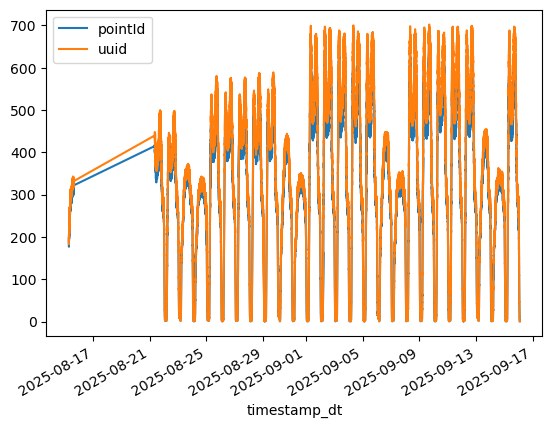

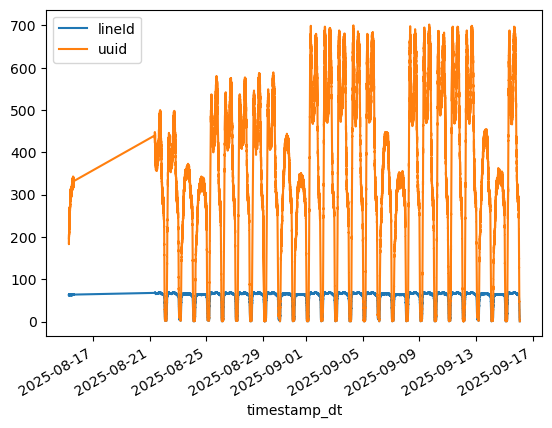

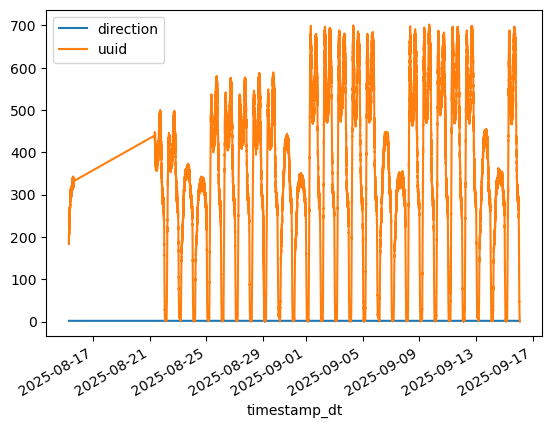

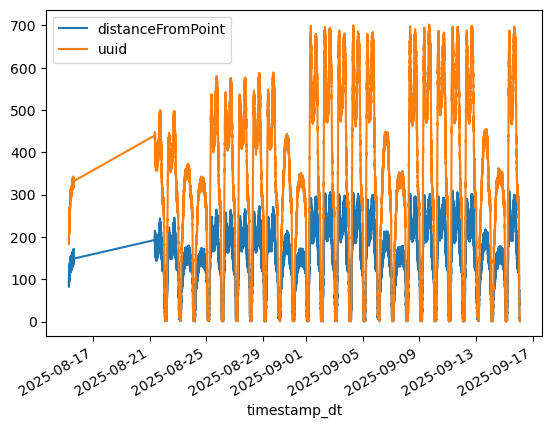

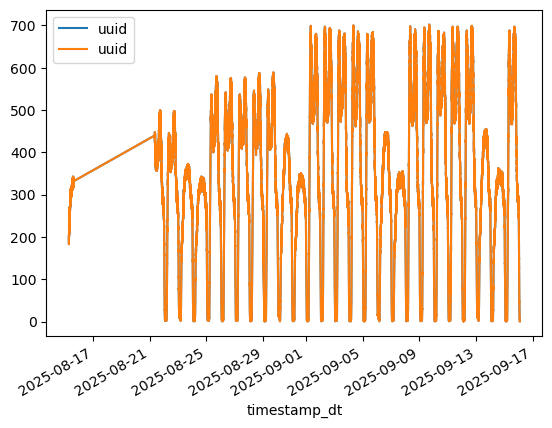

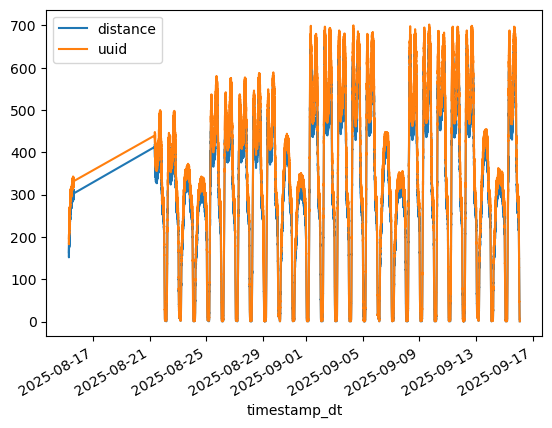

In [23]:
for c in all_uniques:
    if(c!='timestamp_dt' and c!='timestamp'):
        all_uniques.plot(x='timestamp_dt', y=[c,'uuid'])

In [110]:
all_counts[all_counts["datetime"].dt.weekday==6].groupby([all_counts["datetime"].dt.hour,all_counts["datetime"].dt.minute]).mean()

timestamp  geometry        id   pointId    lineId  \
datetime datetime                                                         
0        0         1.756928e+09  1.727273  1.727273  1.727273  1.727273   
         1         1.756983e+09  1.727273  1.727273  1.727273  1.727273   
         2         1.756901e+09  1.750000  1.750000  1.750000  1.750000   
         3         1.756901e+09  1.333333  1.333333  1.333333  1.333333   
         4         1.756901e+09  1.083333  1.083333  1.083333  1.083333   
...                         ...       ...       ...       ...       ...   
23       55        1.756904e+09  2.727273  2.727273  2.727273  2.727273   
         56        1.756987e+09  2.583333  2.583333  2.583333  2.583333   
         57        1.756987e+09  2.333333  2.333333  2.333333  2.333333   
         58        1.756987e+09  2.500000  2.500000  2.500000  2.500000   
         59        1.756987e+09  2.416667  2.416667  2.416667  2.416667   

                   direction  distanceFromPoint      uuid  distance  \
datetime datetime                                                     
0        0          1.727273           1.727273  1.727273  1.727273   
         1          1.727273           1.727273  1.727273  1.727273   
         2          1.750000           1.750000  1.750000  1.750000   
         3          1.333333           1.333333  1.333333  1.333333   
         4          1.083333           1.083333  1.083333  1.083333   
...                      ...                ...       ...       ...   
23       55         2.727273           2.727273  2.727273  2.727273   
         56         2.583333           2.583333  2.583333  2.583333   
         57         2.333333           2.333333  2.333333  2.333333   
         58         2.500000           2.500000  2.500000  2.500000   
         59         2.416667           2.416667  2.416667  2.416667   

                                       datetime  
datetime datetime                                
0        0        2025-09-03 19:38:41.510023936  
         1        2025-09-04 10:55:58.801482752  
         2        2025-09-03 12:02:24.543552256  
         3        2025-09-03 12:03:27.302602496  
         4        2025-09-03 12:04:28.991584256  
...                                         ...  
23       55       2025-09-03 13:00:58.616529152  
         56       2025-09-04 11:56:29.363540992  
         57       2025-09-04 11:57:30.063810304  
         58       2025-09-04 11:58:30.693919488  
         59       2025-09-04 11:59:31.447156480  

[1387 rows x 10 columns]

In [28]:
all_counts["timestamp_dt"].dt.hour

0         7
1         7
2         7
3         7
4         7
         ..
106257    1
106258    1
106259    1
106260    1
106261    1
Name: timestamp_dt, Length: 106262, dtype: int32

<Axes: title={'center': 'Number of rows depending on the time of the day'}, xlabel='Hour'>

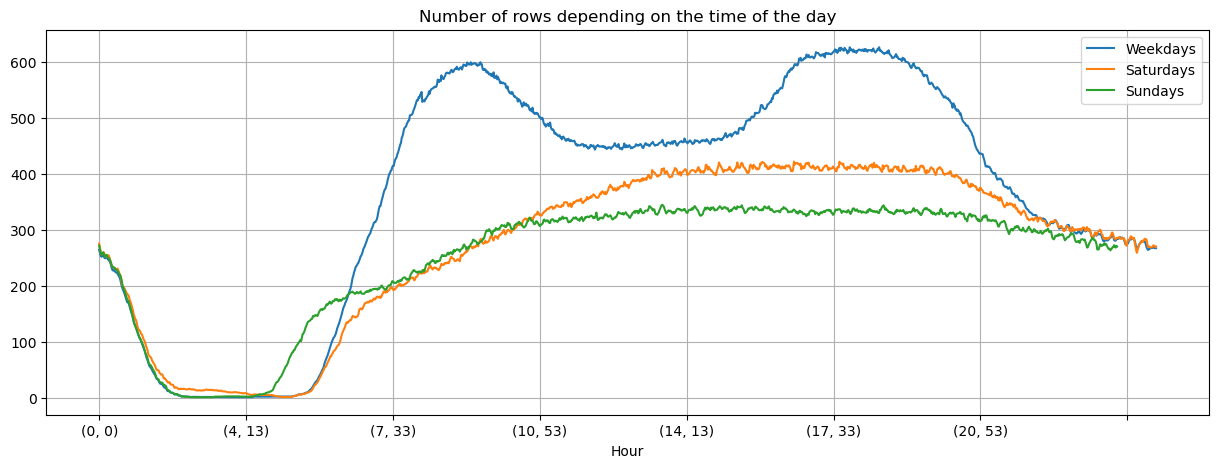

In [25]:
fig=all_counts[all_counts["timestamp_dt"].dt.weekday<5].groupby([all_counts["timestamp_dt"].dt.hour,all_counts["timestamp_dt"].dt.minute]).mean().plot(figsize=(15, 5), y='id', label='Weekdays', grid=True, xlabel='Hour')
#Week-ends
fig=all_counts[all_counts["timestamp_dt"].dt.weekday==5].groupby([all_counts["timestamp_dt"].dt.hour,all_counts["timestamp_dt"].dt.minute]).mean().plot(figsize=(15, 5), y='id', label='Saturdays', grid=True, xlabel='Hour', ax=fig)
all_counts[all_counts["timestamp_dt"].dt.weekday==6].groupby([all_counts["timestamp_dt"].dt.hour,all_counts["timestamp_dt"].dt.minute]).mean().plot(figsize=(15, 5), y='id', label='Sundays', title='Number of rows depending on the time of the day', grid=True, xlabel='Hour',ax=fig)

## Lien pointId et Geometry

In [155]:
start_date=datetime.date.fromisoformat('2025-08-15')
end_date=datetime.date.fromisoformat('2025-09-16')

date=start_date
dfs=[]
Geos=[]
while date<end_date:
    fname='day_positions('+str(date)+').pkl'
    try:
        day_positions=pd.read_pickle(fname)
        day_positions=day_positions.drop_duplicates(['pointId','geometry','lineId'])
        day_positions=day_positions.sort_values('timestamp')
        dfs.append(day_positions)
        Geos.append(pointGeo_group)
        print(date)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_days=pd.concat(dfs)
all_days

2025-08-15
2025-08-16 not found
2025-08-17 not found
2025-08-18 not found
2025-08-19 not found
2025-08-20 not found
2025-08-21
2025-08-22
2025-08-23
2025-08-24
2025-08-25
2025-08-26
2025-08-27
2025-08-28
2025-08-29
2025-08-30
2025-08-31
2025-09-01
2025-09-02
2025-09-03
2025-09-04
2025-09-05
2025-09-06
2025-09-07
2025-09-08
2025-09-09
2025-09-10
2025-09-11
2025-09-12
2025-09-13
2025-09-14


,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,uuid,distance
0,POINT (4.46454 50.84187),136,8161,1,1,0,1.755235e+09,65f4bb82-a380-474c-9178-a75d1cf70a11,0.000000
1,POINT (4.35217 50.8501),51,8011,1,1,0,1.755235e+09,6eda6c2a-4de0-40f1-9c79-c1b3618fc814,9387.896083
2,POINT (4.43566 50.84753),0,8131,1,1,1,1.755235e+09,f69a6192-e661-457e-afd2-872758e6cf1b,2735.984797
3,POINT (4.38183 50.84276),197,8062,1,2,0,1.755235e+09,6cc43a02-782d-488c-998d-47c926747d66,5467.604076
4,POINT (4.32095 50.849),207,8733,1,2,0,1.755235e+09,77a8412d-a368-4cb6-ab97-d319d9619d9f,0.000000
...,...,...,...,...,...,...,...,...,...
48,POINT (4.41151 50.84358),121,1152,28,1,42,1.757881e+09,f3c30ea5-fbe3-4110-871c-9e37bdc22c97,3256.723386
36,POINT (4.3586 50.85609),131,539,25,1,0,1.757884e+09,d2772e0e-dc8e-49dc-830e-40a7d88f5e42,0.000000
38,POINT (4.36028 50.86076),197,539,25,1,48,1.757884e+09,d2772e0e-dc8e-49dc-830e-40a7d88f5e42,537.736963
223,POINT (4.29077 50.87246),148,2845,83,2,8,1.757887e+09,cb9c7228-6c59-49ff-adef-4a821b84c681,119.743420


In [156]:
all_days.sort_values(['pointId', 'geometry','lineId'])

,geometry,id,pointId,lineId,direction,distanceFromPoint,timestamp,uuid,distance
51,POINT (4.41155 50.83679),148,89,39,2,48,1.755236e+09,bd899646-34f3-47ca-9d17-014496aba882,281.925693
112,POINT (4.41155 50.83679),208,89,39,2,80,1.755759e+09,ae4c8634-7ee0-4c9e-b0ed-364d29d9b462,281.925693
59,POINT (4.41155 50.83679),33,89,39,2,34,1.755814e+09,8f00cadb-3223-4833-af3c-85405872b0eb,281.925693
64,POINT (4.41155 50.83679),82,89,39,2,55,1.755901e+09,813b8c7e-c818-4ea5-bce0-39e4d8b528ea,281.925693
62,POINT (4.41155 50.83679),136,89,39,2,82,1.755987e+09,84c72756-6092-4a92-ab55-ab8dbf6a4700,281.925693
...,...,...,...,...,...,...,...,...,...
175,POINT (4.35365 50.81196),70,9969,7,1,0,1.757455e+09,58cb6345-3be6-466f-b86c-e299d7fdc011,15590.859214
172,POINT (4.35365 50.81196),83,9969,7,1,0,1.757542e+09,62ca2b59-c229-426d-9b77-4e1669d07d0b,15590.859214
169,POINT (4.35365 50.81196),116,9969,7,1,0,1.757628e+09,507b5d03-dc13-4994-86e8-c1bb762448b9,15590.859214
184,POINT (4.35365 50.81196),34,9969,7,1,0,1.757714e+09,d825c816-febe-4918-9989-de633ab67708,15590.859214


In [211]:
start_date=datetime.date.fromisoformat('2025-09-06')
end_date=datetime.date.fromisoformat('2025-09-07')

date=start_date
dfs=[]
Geos=[]
while date<end_date:
    fname='day_positions('+str(date)+').pkl'
    try:
        day_positions=pd.read_pickle(fname)
        day_positions=day_positions.assign(time=pd.to_datetime(day_positions['timestamp'], unit='s'))

        day_positions=day_positions.sort_values('timestamp')
        pointId_group=day_positions[['geometry', 'pointId','lineId','direction', 'distanceFromPoint', 'distance','timestamp']].groupby(['pointId','geometry','lineId']).agg(['min','max','count'])
        pointGeo_group=day_positions[['geometry', 'pointId','lineId','direction', 'distanceFromPoint', 'distance','timestamp']].groupby(['geometry','pointId','lineId']).agg(['min','max','count'])
        dfs.append(pointId_group)
        Geos.append(pointGeo_group)
        print(date)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_Ids=pd.concat(dfs)
all_Geos=pd.concat(Geos)

2025-09-06


In [66]:
all_Ids

direction           distanceFromPoint  \
                                              min max count               min   
pointId geometry                 lineId                                         
89      POINT (4.40897 50.83801) 39             2   2   884                 0   
        POINT (4.41155 50.83679) 39             2   2   170                33   
471     POINT (4.3244 50.87121)  9              2   2   517                 1   
        POINT (4.32919 50.86376) 9              2   2   302                 0   
472     POINT (4.32441 50.86389) 9              1   1   545                 1   
...                                           ...  ..   ...               ...   
9876    POINT (4.45033 50.85649) 42             2   2    45                 0   
9963    POINT (4.35422 50.81184) 7              2   2  2207                 0   
        POINT (4.35536 50.81168) 7              2   2    45                20   
9969    POINT (4.35268 50.81215) 7              1   1    13                 6   
        POINT (4.35365 50.81196) 7              1   1  1909                 0   

                                                        distance  \
                                         max count           min   
pointId geometry                 lineId                            
89      POINT (4.40897 50.83801) 39        0   884      0.404851   
        POINT (4.41155 50.83679) 39      245   170    281.925693   
471     POINT (4.3244 50.87121)  9       514   517   4999.875670   
        POINT (4.32919 50.86376) 9         0   302   4101.314034   
472     POINT (4.32441 50.86389) 9       336   545   6047.238737   
...                                      ...   ...           ...   
9876    POINT (4.45033 50.85649) 42        0    45   3340.249241   
9963    POINT (4.35422 50.81184) 7         0  2207    462.245322   
        POINT (4.35536 50.81168) 7        47    45    544.339367   
9969    POINT (4.35268 50.81215) 7        37    13  15662.559981   
        POINT (4.35365 50.81196) 7         0  1909  15590.859214   

                                                                timestamp  \
                                                  max count           min   
pointId geometry                 lineId                                     
89      POINT (4.40897 50.83801) 39          0.404851   884  1.757110e+09   
        POINT (4.41155 50.83679) 39        281.925693   170  1.757110e+09   
471     POINT (4.3244 50.87121)  9        4999.875670   517  1.757110e+09   
        POINT (4.32919 50.86376) 9        4101.314034   302  1.757110e+09   
472     POINT (4.32441 50.86389) 9        6047.238737   545  1.757110e+09   
...                                               ...   ...           ...   
9876    POINT (4.45033 50.85649) 42       3340.249241    45  1.757139e+09   
9963    POINT (4.35422 50.81184) 7         462.245322  2207  1.757110e+09   
        POINT (4.35536 50.81168) 7         544.339367    45  1.757110e+09   
9969    POINT (4.35268 50.81215) 7       15662.559981    13  1.757128e+09   
        POINT (4.35365 50.81196) 7       15590.859214  1909  1.757110e+09   

                                                             
                                                  max count  
pointId geometry                 lineId                      
89      POINT (4.40897 50.83801) 39      1.757198e+09   884  
        POINT (4.41155 50.83679) 39      1.757198e+09   170  
471     POINT (4.3244 50.87121)  9       1.757198e+09   517  
        POINT (4.32919 50.86376) 9       1.757198e+09   302  
472     POINT (4.32441 50.86389) 9       1.757198e+09   545  
...                                               ...   ...  
9876    POINT (4.45033 50.85649) 42      1.757197e+09    45  
9963    POINT (4.35422 50.81184) 7       1.757199e+09  2207  
        POINT (4.35536 50.81168) 7       1.757198e+09    45  
9969    POINT (4.35268 50.81215) 7       1.757196e+09    13  
        POINT (4.35365 50.81196) 7       1.757199e+09  1909  

[563

In [98]:
one_id=all_Ids.sample(1).index[0][0]
subgdf=all_Ids.query("(pointId==2633)")
subgdf

direction           distanceFromPoint  \
                                              min max count               min   
pointId geometry                 lineId                                         
2633    POINT (4.32794 50.80431) 48             2   2   329                 1   
        POINT (4.32845 50.80703) 48             2   2    45                 0   

                                                       distance               \
                                         max count          min          max   
pointId geometry                 lineId                                        
2633    POINT (4.32794 50.80431) 48      315   329  7411.264958  7411.264958   
        POINT (4.32845 50.80703) 48        0    45  7106.841642  7106.841642   

                                                  timestamp                \
                                        count           min           max   
pointId geometry                 lineId                                     
2633    POINT (4.32794 50.80431) 48       329  1.757110e+09  1.757198e+09   
        POINT (4.32845 50.80703) 48        45  1.757110e+09  1.757196e+09   

                                               
                                        count  
pointId geometry                 lineId        
2633    POINT (4.32794 50.80431) 48       329  
        POINT (4.32845 50.80703) 48        45

## Cartes aléatoires
Prend une ligne au hasard et montre la position des autres lignes avec la même valeur pour une colonne donnée.

Là: avec le même "pointId"

In [46]:
input_dir='data/daily positions/'
fname='day_positions(2025-09-01).pkl'
try:
    day_positions=pd.read_pickle(input_dir+fname)

    day_positions=day_positions.sort_values('timestamp')
except FileNotFoundError:
    print(date,'not found')

Ici, le même "uuid". C'est-à-dire, on suit le parcours d'un bus.

Les cercles représentent la valeur de "distanceFromPoint"

In [58]:
p=day_positions.query("lineId=='1'").sample(1)
v=p['uuid'].max()
#v='42f4e447-b06c-4ed7-b7c0-cabae104fbef'#'f6bafbdf-6ed4-4ad9-81da-9e19ca4e933f'#'ae74b590-f8ee-4919-9f04-006d3b8b06ee'#'d390ad7a-2abe-46aa-a418-ddfaea5cebce'#v='4e853ca1-bacc-4efa-87e9-5ebdb1eba4c8'
subgdf=day_positions.query("(uuid==@v)")
print(len(subgdf))
subgdf=subgdf.assign(buff=subgdf.to_crs('epsg:3857').buffer(subgdf['distanceFromPoint']).boundary.to_crs('epsg:4326'))
m=subgdf.set_geometry('buff').explore('timestamp_dt', cmap='cool')
subgdf.query('distanceFromPoint==0').explore('timestamp_dt', cmap='cool',m=m)

80


On voit que la position indiquée est celle d'un arrêt et que les cercles grandissent avec le temps (distances depuis le précédent arrêt ?)

C:\Users\anieb\anaconda3\envs\datamine\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
C:\Users\anieb\anaconda3\envs\datamine\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


Text(0.5, 1.0, 'Line 92')

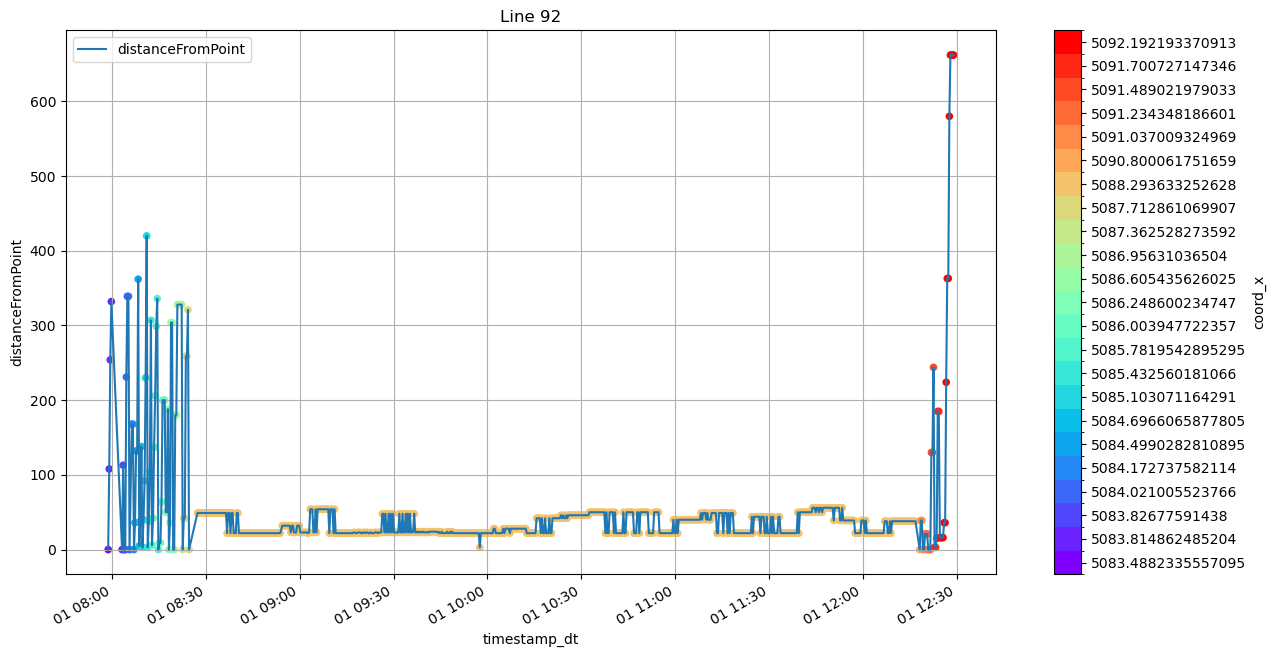

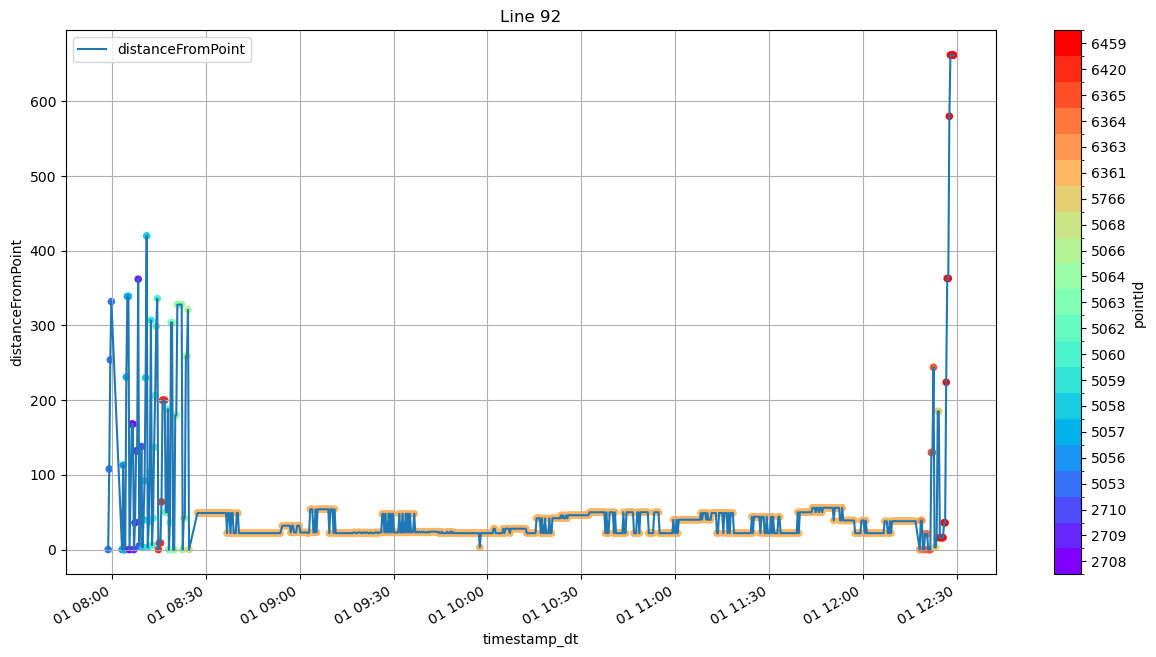

In [44]:
subgdf=subgdf.assign(pointId=subgdf['pointId'].astype("category"), coord_x=(subgdf['geometry'].y*100+subgdf['geometry'].x).astype("category"))

ax=subgdf.plot.scatter(x='timestamp_dt', y='distanceFromPoint', grid=True, cmap='rainbow',c='coord_x',figsize=(15,8))#'pointId')
subgdf.plot.line(x='timestamp_dt', y='distanceFromPoint', grid=True,ax=ax)
plt.title('Line '+subgdf.iloc[0,:]['lineId'])
ax=subgdf.plot.scatter(x='timestamp_dt', y='distanceFromPoint', grid=True, cmap='rainbow',c='pointId',figsize=(15,8))
subgdf.plot.line(x='timestamp_dt', y='distanceFromPoint', grid=True,ax=ax)
plt.title('Line '+subgdf.iloc[0,:]['lineId'])

## Check the gap between timestamp
By Antoine

In [45]:
input_dir='data/daily positions/'
start_date=datetime.date.fromisoformat('2025-08-15')
end_date=datetime.date.fromisoformat('2025-09-16')
date=start_date
dfs=[]
uniques=[]
uniques_per_day=[]
while date<end_date:
    fname='day_positions('+str(date)+').pkl'
    try:
        day_positions=pd.read_pickle(input_dir+fname)

        day_positions=day_positions.sort_values('timestamp')
        day_time=day_positions.drop_duplicates('timestamp_dt')[['timestamp_dt','id']]
        dfs.append(day_time)
        print(date)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_times=pd.concat(dfs)
all_times=all_times.drop_duplicates('timestamp_dt').reset_index(drop=True)

2025-08-15
2025-08-16 not found
2025-08-17 not found
2025-08-18 not found
2025-08-19 not found
2025-08-20 not found
2025-08-21
2025-08-22
2025-08-23
2025-08-24
2025-08-25
2025-08-26
2025-08-27
2025-08-28
2025-08-29
2025-08-30
2025-08-31
2025-09-01
2025-09-02
2025-09-03
2025-09-04
2025-09-05
2025-09-06
2025-09-07
2025-09-08
2025-09-09
2025-09-10
2025-09-11
2025-09-12
2025-09-13
2025-09-14
2025-09-15


In [46]:
all_times

,timestamp_dt,id
0,2025-08-15 07:20:13.152456045+02:00,136
1,2025-08-15 07:20:33.641208887+02:00,45
2,2025-08-15 07:20:53.867563963+02:00,113
3,2025-08-15 07:21:14.085609913+02:00,66
4,2025-08-15 07:21:34.304517031+02:00,89
...,...,...
106257,2025-09-16 01:58:37.534430027+02:00,0
106258,2025-09-16 01:58:57.751841068+02:00,0
106259,2025-09-16 01:59:17.946391106+02:00,0
106260,2025-09-16 01:59:38.111557007+02:00,0


In [50]:
import time

In [60]:
 # --- Config ---
GAP_SECONDS =  60  # 1 minute

# --- Start timer ---
t0 = time.time()
# --- Ensure chronological order ---
gdf2 = all_times.sort_values("timestamp_dt").reset_index(drop=True)
# --- Compute time differences ---
gdf2["time_diff"] = gdf2["timestamp_dt"].diff()

# --- Filter for gaps > 5 minutes ---
gaps = gdf2[gdf2["time_diff"] > pd.Timedelta(seconds=GAP_SECONDS)].copy()
# --- Compute readable details ---
gaps["gap_start"] = gdf2["timestamp_dt"].shift()[gaps.index]
gaps["gap_end"] = gaps["timestamp_dt"]
#gaps["gap_duration_sec"] = gaps["time_diff"]
#gaps["gap_duration_min"] = gaps["time_diff"] / 60
# --- Stop timer ---
t1 = time.time()
elapsed = t1 - t0
# --- Print summary ---
print(f"\n Number of gaps > 1 minutes: {len(gaps)}")
print(f" Computation time: {elapsed:.2f} seconds\n")

print("List of gaps:")
for _, row in gaps.iterrows():
    print(f"{row['gap_start'].round('s')}  →  {row['gap_end'].round('s')}  |  {row['time_diff'].round('s')}")

# Optional: inspect results DataFrame
# print(gaps[["gap_start", "gap_end", "gap_duration_min"]])


 Number of gaps > 1 minutes: 25
 Computation time: 0.02 seconds

List of gaps:
2025-08-15 15:32:24+02:00  →  2025-08-21 08:42:18+02:00  |  5 days 17:09:55
2025-08-22 02:02:38+02:00  →  2025-08-22 03:30:32+02:00  |  0 days 01:27:54
2025-08-24 02:36:45+02:00  →  2025-08-24 03:30:31+02:00  |  0 days 00:53:46
2025-08-25 02:03:10+02:00  →  2025-08-25 03:30:36+02:00  |  0 days 01:27:25
2025-08-25 19:22:42+02:00  →  2025-08-25 19:52:01+02:00  |  0 days 00:29:20
2025-08-27 02:03:11+02:00  →  2025-08-27 03:30:36+02:00  |  0 days 01:27:25
2025-08-29 02:22:46+02:00  →  2025-08-29 02:27:09+02:00  |  0 days 00:04:23
2025-08-29 02:36:56+02:00  →  2025-08-29 02:38:58+02:00  |  0 days 00:02:02
2025-08-29 02:59:55+02:00  →  2025-08-29 03:11:43+02:00  |  0 days 00:11:49
2025-08-29 03:29:45+02:00  →  2025-08-29 03:30:46+02:00  |  0 days 00:01:01
2025-08-30 03:13:35+02:00  →  2025-08-30 04:00:11+02:00  |  0 days 00:46:37
2025-08-31 02:07:35+02:00  →  2025-08-31 03:30:39+02:00  |  0 days 01:23:04
2025-09-

## Vehicles between two days

In [78]:
pre_24_uuids=day_positions.query("timestamp_dt<@tomorrow")['uuid'].unique()
post_24_uuids=day_positions.query("timestamp_dt>@tomorrow")['uuid'].unique()

In [38]:
input_dir='data/daily positions/'
start_date=pd.Timestamp('2025-08-15', tz='UTC+02:00')
end_date=pd.Timestamp('2025-09-16', tz='UTC+02:00')
date=start_date
dfs=[]
uniques=[]
uniques_per_day=[]
while date<end_date:
    fname='day_positions('+str(date.date())+').pkl'
    try:
        day_positions=pd.read_pickle(input_dir+fname)
        day_positions=day_positions.sort_values('timestamp')

        tomorrow=date+datetime.timedelta(days=1)
        pre_24_uuids=day_positions.query("timestamp_dt<@tomorrow")['uuid'].unique()
        post_24_uuids=day_positions.query("timestamp_dt>@tomorrow")['uuid'].unique()
        tomorrow_uuids=np.setdiff1d(post_24_uuids,pre_24_uuids, assume_unique=True)
        today_into_tomorrow_uuids=np.intersect1d(post_24_uuids,pre_24_uuids, assume_unique=True)

        inter_days_positions=day_positions[day_positions['uuid'].isin(today_into_tomorrow_uuids)]
        
        dfs.append(inter_days_positions)
        print(date.date())
        print(f"Nombre de véhicule du jour circulant le lendemain:{len(today_into_tomorrow_uuids)}")
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_inter_positions=pd.concat(dfs)
#all_times=all_times.drop_duplicates('timestamp_dt').reset_index(drop=True)

2025-08-15
Nombre de véhicule du jour circulant le lendemain:0
2025-08-16 00:00:00+02:00 not found
2025-08-17 00:00:00+02:00 not found
2025-08-18 00:00:00+02:00 not found
2025-08-19 00:00:00+02:00 not found
2025-08-20 00:00:00+02:00 not found
2025-08-21
Nombre de véhicule du jour circulant le lendemain:268
2025-08-22
Nombre de véhicule du jour circulant le lendemain:267
2025-08-23
Nombre de véhicule du jour circulant le lendemain:266
2025-08-24
Nombre de véhicule du jour circulant le lendemain:267
2025-08-25
Nombre de véhicule du jour circulant le lendemain:258
2025-08-26
Nombre de véhicule du jour circulant le lendemain:264
2025-08-27
Nombre de véhicule du jour circulant le lendemain:267
2025-08-28
Nombre de véhicule du jour circulant le lendemain:265
2025-08-29
Nombre de véhicule du jour circulant le lendemain:276
2025-08-30
Nombre de véhicule du jour circulant le lendemain:271
2025-08-31
Nombre de véhicule du jour circulant le lendemain:267
2025-09-01
Nombre de véhicule du jour circ

In [39]:
uuid_groups=all_inter_positions.groupby('uuid')['timestamp_dt'].agg(['min','max', 'count'])
uuid_groups=uuid_groups.sort_values('min')
uuid_groups

,min,max,count
uuid,,,
74a6006c-d15f-4f4f-8d2c-32acd0b4a7d3,2025-08-21 08:42:38.746335983+02:00,2025-08-22 00:31:56.452945948+02:00,2794
79dae7b3-21a8-4ec3-97a3-299bb20b4926,2025-08-21 10:53:11.507541895+02:00,2025-08-22 01:21:10.974781990+02:00,2554
a90d3c82-50ea-40c7-9fdf-be63a87c9ce0,2025-08-21 20:04:16.386287928+02:00,2025-08-22 00:57:09.717022896+02:00,863
2ad27ed8-c0a7-4450-8362-1f2cf8072dd3,2025-08-21 21:53:51.783900023+02:00,2025-08-22 00:09:18.729995966+02:00,400
f0fc49ae-64c4-4e62-9ede-1fc14d4d3052,2025-08-21 22:19:31.499061108+02:00,2025-08-22 00:49:43.984891891+02:00,443
...,...,...,...
3bbdf789-706f-4920-83e1-7d31519881c4,2025-09-15 23:59:25.504856109+02:00,2025-09-16 00:40:34.154506922+02:00,121
6bcb736d-a8ba-443d-8ca5-84ae319e5020,2025-09-15 23:59:45.861499071+02:00,2025-09-16 00:26:56.922938108+02:00,72
1cef26dd-7c7f-4007-9924-ee5dffec63e6,2025-09-15 23:59:45.861499071+02:00,2025-09-16 00:04:16.395416021+02:00,14


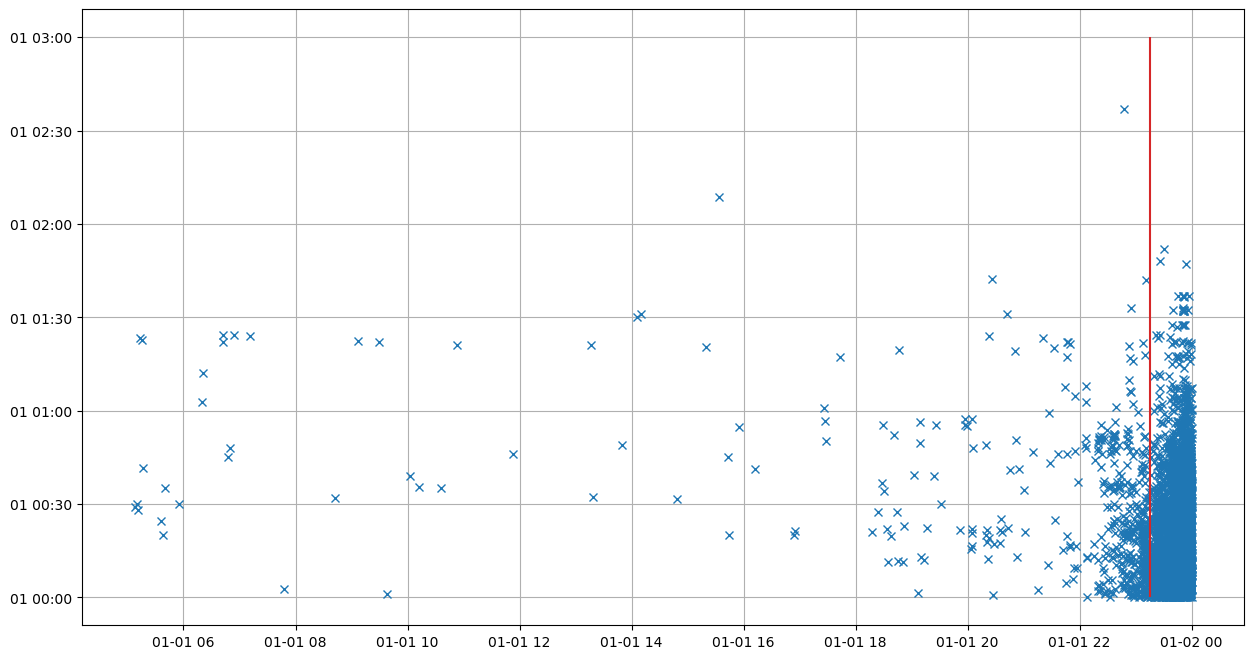

In [45]:
plt.figure(figsize=(15, 8))
plt.plot(uuid_groups['min'].apply(lambda x:x.replace(month=1, day=1)),
         uuid_groups['max'].apply(lambda x:x.replace(month=1, day=1)),
         
        'x')
plt.grid()
plt.vlines(pd.Timestamp('2025-01-01 23:15:00+02:00'),pd.Timestamp('2025-01-01 00:00:00+02:00'),pd.Timestamp('2025-01-01 03:00:00+02:00'), colors="tab:red")


In [43]:
all_inter_positions.groupby(['lineId']).nunique().sort_values('uuid')

,geometry,id,pointId,direction,distanceFromPoint,timestamp,uuid,distance,timestamp_dt
lineId,,,,,,,,,
72,5,99,4,1,118,1480,14,5,1480
33,15,269,12,2,273,2175,21,16,2175
44,15,262,14,2,333,825,28,16,825
75,22,215,21,2,356,1713,31,22,1713
73,19,212,18,2,308,2421,41,20,2421
...,...,...,...,...,...,...,...,...,...
93,54,338,49,2,582,12222,197,79,12222
6,51,231,50,2,2,5326,202,87,5326
95,50,406,46,2,664,17543,205,94,17543


## Arrêts dessservis par chaque uuid

In [30]:
dp_line_u.sort_values('timestamp_dt').groupby('uuid').cumcount()

0        0
1        0
7        1
8        1
13       2
        ..
6646    17
6650     0
6644     3
6645     4
6655     1
Length: 1304, dtype: int64

In [ ]:
input_dir='data/daily positions/'
start_date=pd.Timestamp('2025-08-15', tz='UTC+02:00')
end_date=pd.Timestamp('2025-09-16', tz='UTC+02:00')
date=start_date
while date<end_date:
    fname='day_positions('+str(date.date())+').pkl'
    try:
        pd.DataFrame(['Salut','Sheet name: line direction']).to_excel(f"data/uuids ({str(date.date())}).xlsx", sheet_name="Intro")
        day_positions=pd.read_pickle(input_dir+fname)
        day_positions=day_positions.sort_values('timestamp')

        day_positions_g=day_positions.groupby(['lineId', 'direction'])
        for name, dp_line in day_positions_g:
            lineId=name[0]
            dir=name[1]
            print('\r',lineId, dir,end='')
            dp_line_u=dp_line.reset_index().drop_duplicates(['pointId','uuid'])
            dp_line_u["point_order"]=dp_line_u.sort_values('timestamp_dt').groupby('uuid').cumcount()
            #t=dp_line_u.groupby(['pointId','uuid'], as_index=False).first()
            final=dp_line_u.pivot(index="pointId", columns="uuid", values="point_order")
            #final['order']=
            final=final.sort_values(final.count().idxmax())
            final.loc['min_time',:]=dp_line_u.groupby('uuid')['timestamp_dt'].min().dt.round(freq='s').dt.time
            final.loc['max_time',:]=dp_line_u.groupby('uuid')['timestamp_dt'].max().dt.round(freq='s').dt.time
            final=final.sort_values(by='min_time', axis=1)
            #print(final)
            final.to_csv(f"data/uuids line {lineId} {dir}({str(date.date())}).csv", sep=';')
            #with pd.ExcelWriter(f"data/uuids ({str(date.date())}).xlsx", mode='a') as writer:
            #    final.to_excel(writer, sheet_name=f'{lineId} {dir}')
        print(date.date())
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_inter_positions=pd.concat(dfs)
#all_times=all_times.drop_duplicates('timestamp_dt').reset_index(drop=True)

## Nombre d'arrêts desservis par chaque véhicule

In [61]:
stops_by_uuid=day_positions.groupby(['lineId', 'uuid'], as_index=False)[['pointId','geometry']].nunique()
stops_by_uuid

,lineId,uuid,pointId,geometry
0,1,01146acd-6691-490a-af36-556c85ae5d5f,20,21
1,1,011bc47f-4254-4735-974d-5f88bc04d963,11,12
2,1,01f9fa85-3f81-4869-acc5-858686636a7c,20,21
3,1,03d8c29e-c4a2-4595-a5ac-88c787eb6927,20,21
4,1,060edd0e-e643-4ced-bb14-8e699ca1bdde,20,21
...,...,...,...,...
23532,95,fe742e0c-a3d1-4925-bfc2-c3fa0d86bc1c,2,1
23533,95,fe8a58c9-77b7-450f-8b37-557c1c413e73,2,2
23534,95,fecfea88-88bc-4594-91bd-bf573ca1a3e0,5,4
23535,95,ff206f90-6996-4b0a-ac99-ea1cd948f665,18,18


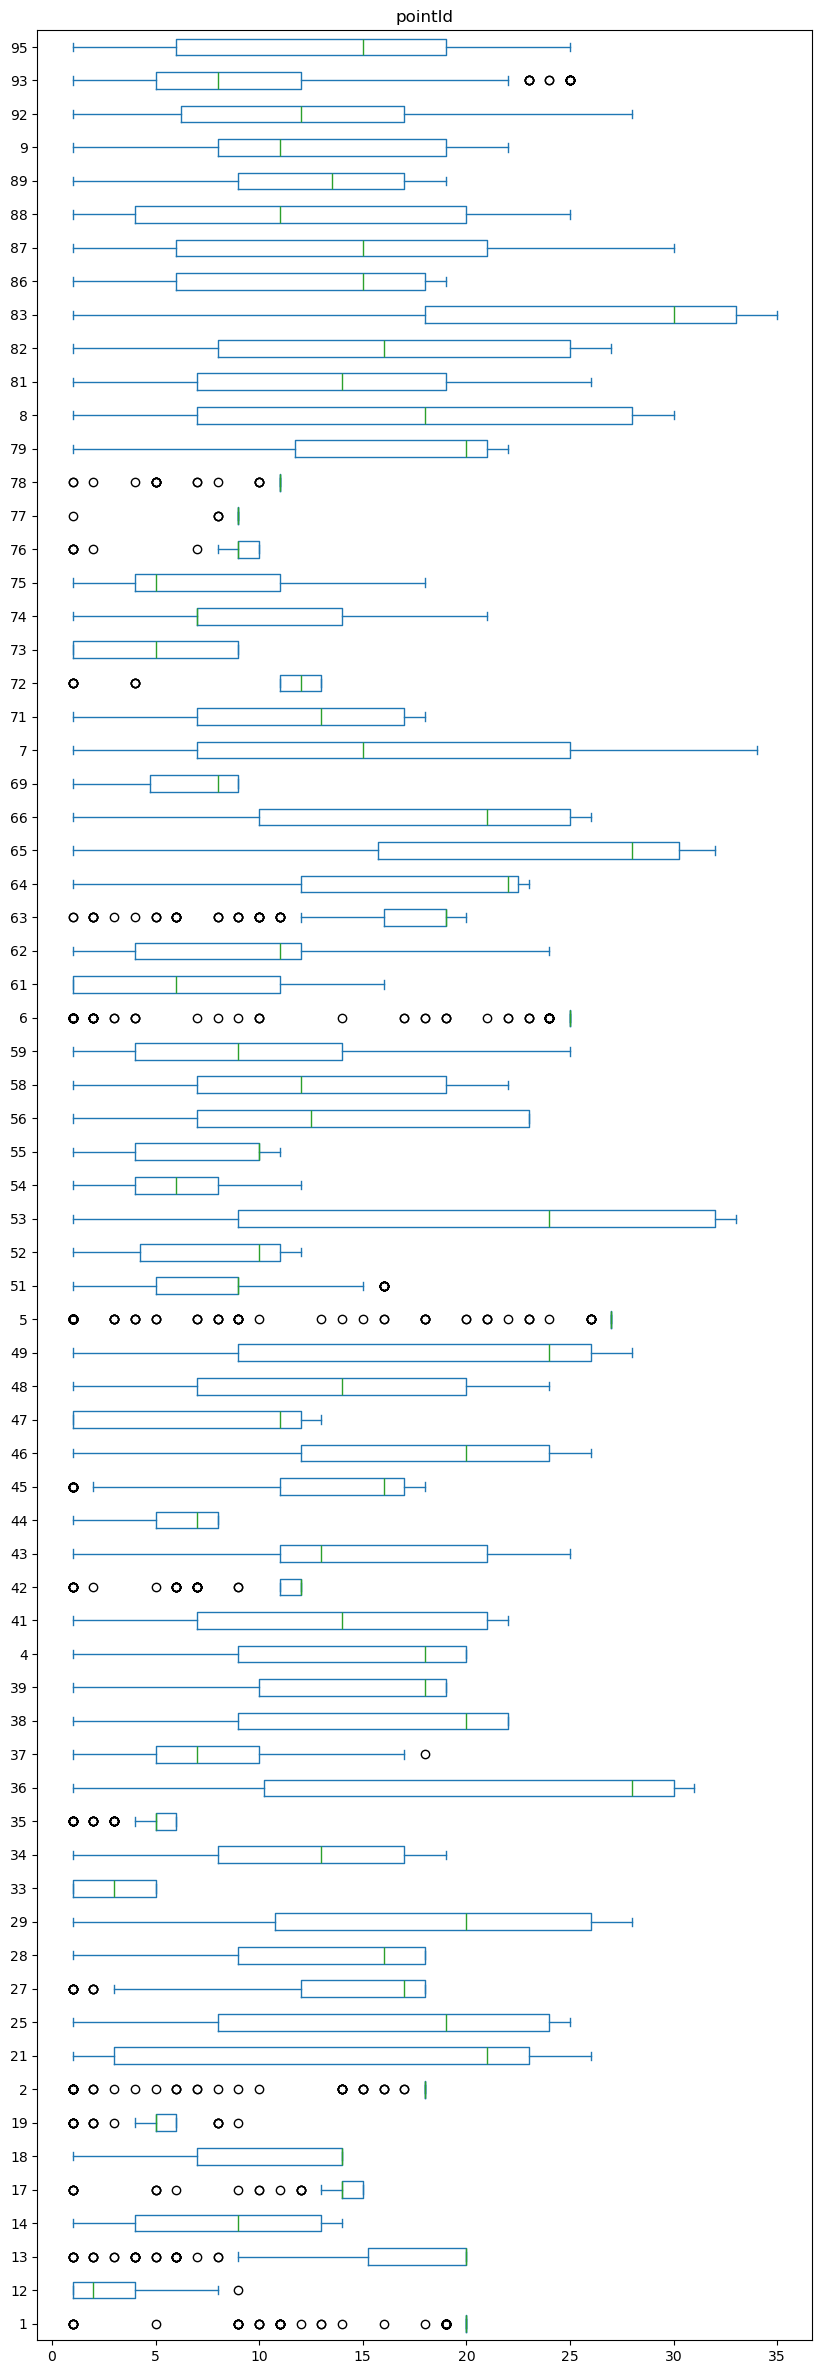

geometry    Axes(0.125,0.11;0.775x0.77)
dtype: object

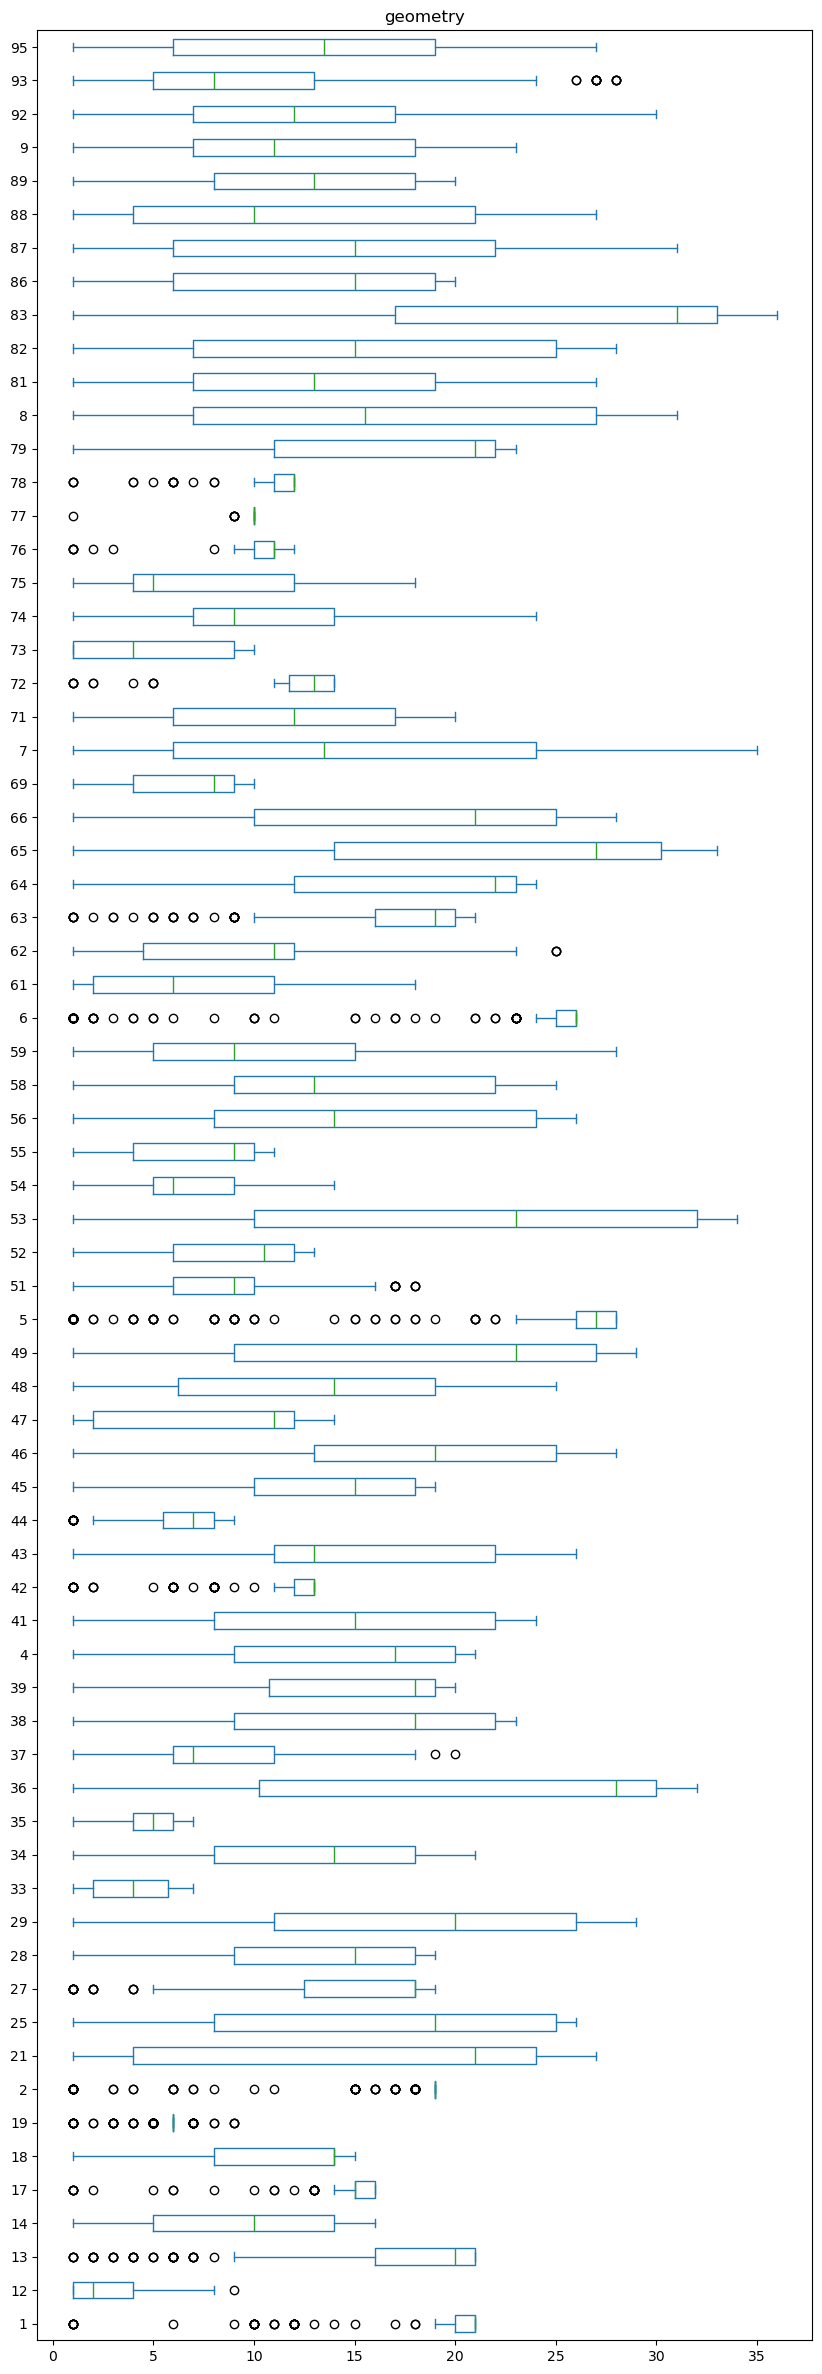

In [66]:
stops_by_uuid.plot.box(column='pointId',by='lineId', 
                       vert=False, figsize=(10,20))
plt.show()
stops_by_uuid.plot.box(column='geometry',by='lineId', 
                       vert=False, figsize=(10,20))

In [67]:
#Je récupère le bon nombre d'arrêts par ligne du GTFS

In [5]:

GTFS_zip_files=['GTFS_2025-08-13T04-20-01.zip', 'GTFS_2025-08-22T04-20-01.zip',
                'GTFS_2025-09-03T04-20-01.zip','GTFS_2025-09-04T04-20-01.zip','GTFS_2025-09-15T04-20-01.zip']
GTFS_dates=['2025-08-13','2025-08-22','2025-09-03','2025-09-04','2025-09-15']
data_dir="data"

Feed infos: GTFS_2025-08-13T04-20-01.zip
Version: 2_18_20250804_010621
From 2025-08-04 00:00:00 to 2025-08-31 00:00:00
Files read              
-------------------2025-08-21-------------------


C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:98: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_ajoute=calendar_dates.query("(exception_type=='1')&(date==@date)")
C:\Users\anieb\OneDrive - Université Libre de Bruxelles\Data Mining\Project\STIB-analysis\utils.py:100: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  exceptions_retire=calendar_dates.query("(exception_type=='2')&(date==@date)")


-------------------2025-08-22-------------------
Feed infos: GTFS_2025-08-22T04-20-01.zip
Version: 2_19_20250818_010705
From 2025-08-18 00:00:00 to 2025-09-14 00:00:00
Files read              


KeyboardInterrupt: 

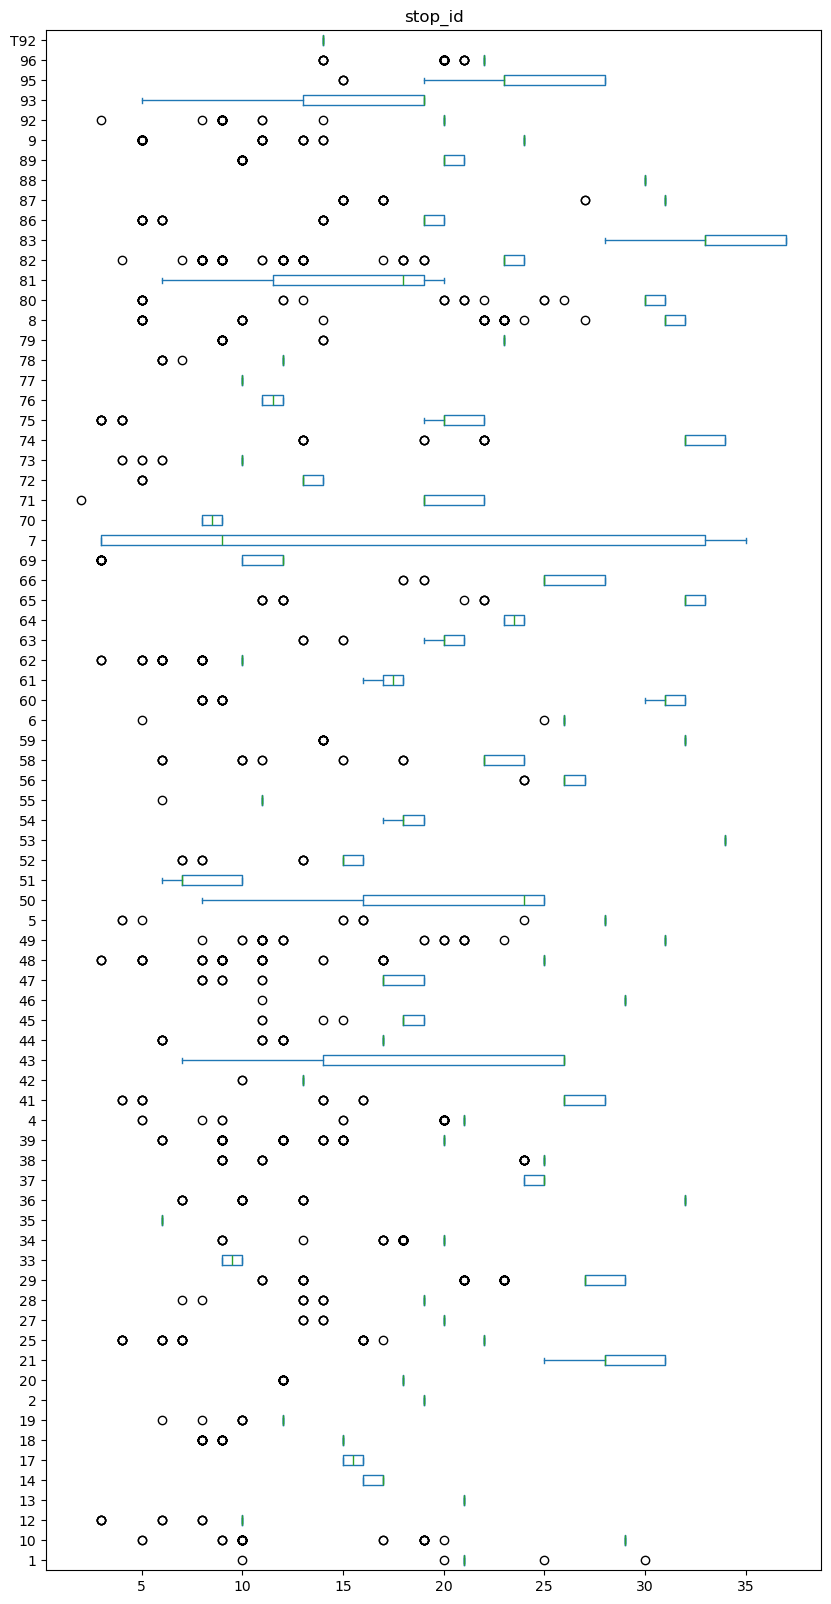

In [6]:
sdate_debut="2025-08-21"#"2025-09-01"#
sdate_fin="2025-09-15"
date_fin=pd.Timestamp(sdate_fin, tz='UTC+02:00')#pd.to_datetime(sdate_fin)
date=pd.Timestamp(sdate_debut, tz='UTC+02:00')

GTFS_i=0
while(sdate_debut>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1

active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
dfs=[]
while date<=date_fin:
    sdate=str(date.date())
    print("-------------------"+sdate+"-------------------")
    if(sdate>=GTFS_dates[GTFS_i+1]):
        GTFS_i=GTFS_i+1
        active_GTFS_zip_file=GTFS_zip_files[GTFS_i]
        geo_stops, stop_times, trips, lines, routes, calendar, calendar_dates = utils.read_gtfs(active_GTFS_zip_file,data_dir)
    active_stop_times, active_trips =utils.get_active_stop_times(sdate, trips, stop_times, calendar, calendar_dates)
    #%% Convert the time columns of active_stop_times to datetime
    active_stop_times=active_stop_times.assign(arrival_datetime=active_stop_times['arrival_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))),
                             departure_datetime=active_stop_times['departure_time'].str.split(':').apply(lambda x:date+datetime.timedelta(hours=int(x[0]), minutes=int(x[1]), seconds=int(x[2]))))

    #%% Fusionne les stop_times actifs et les routes
    act=active_trips[['route_id', 'trip_id', 'direction_id', 'shape_id']].merge(active_stop_times, on='trip_id', how='outer')
    r=routes[['route_id', 'route_short_name','route_type']]
    r.assign(route_short_name=r['route_short_name'].astype('string'))
    act=act.merge(r, on='route_id', how='outer', indicator=True)
    act=act[act['_merge']!="right_only"]
    act=act.drop('_merge',axis=1)
    act=act.assign(route_short_name=act['route_short_name'].astype('string'))
    #Fusion des stop_times actifs et geo_stops
    #gstops=geo_stops[['stop_id', 'stop_name', 'location_type', 'parent_station', 'geometry']]
    #gstops=gstops.rename(columns={'geometry':'stop_geo'})
    #act=gstops.merge(act, on='stop_id', how='outer', indicator=True)
    #print("Résultat de la fusion entre les arrêts et les stop_times actifs(horaire du jour)")
    #print(act['_merge'].value_counts())#484 stops not in the active stop_times
    #act=act[act['_merge']!="left_only"]
    #act=act.drop('_merge',axis=1)
    #act=act.assign(stop_id=act['stop_id'].astype('string'))

    stops_by_uuid=act.groupby(['route_short_name', 'trip_id'], as_index=False)[['stop_id']].nunique()
    stops_by_uuid.plot.box(column='stop_id',by='route_short_name', 
                           vert=False, figsize=(10,20))
    
    date=date+pd.Timedelta(value=1, unit='day')
all_inter_GTFS=pd.concat(dfs)

        

In [ ]:
input_dir='data/daily positions/'
start_date=pd.Timestamp('2025-08-15', tz='UTC+02:00')
end_date=pd.Timestamp('2025-09-16', tz='UTC+02:00')
date=start_date
dfs=[]
uniques=[]
uniques_per_day=[]
while date<end_date:
    fname='day_positions('+str(date.date())+').pkl'
    try:
        day_positions=pd.read_pickle(input_dir+fname)
        day_positions=day_positions.sort_values('timestamp')

        tomorrow=date+datetime.timedelta(days=1)
        pre_24_uuids=day_positions.query("timestamp_dt<@tomorrow")['uuid'].unique()
        post_24_uuids=day_positions.query("timestamp_dt>@tomorrow")['uuid'].unique()
        tomorrow_uuids=np.setdiff1d(post_24_uuids,pre_24_uuids, assume_unique=True)
        today_into_tomorrow_uuids=np.intersect1d(post_24_uuids,pre_24_uuids, assume_unique=True)

        inter_days_positions=day_positions[day_positions['uuid'].isin(today_into_tomorrow_uuids)]
        
        dfs.append(inter_days_positions)
        print(date.date())
        print(f"Nombre de véhicule du jour circulant le lendemain:{len(today_into_tomorrow_uuids)}")
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_inter_positions=pd.concat(dfs)
#all_times=all_times.drop_duplicates('timestamp_dt').reset_index(drop=True)

## distanceFromPoint = 0

In [11]:
input_dir='data/daily positions/'
start_date=pd.Timestamp('2025-08-15', tz='UTC+02:00')
end_date=pd.Timestamp('2025-09-16', tz='UTC+02:00')
date=start_date
dfs=[]
dfs_geo=[]
while date<end_date:
    fname='day_positions('+str(date.date())+').pkl'
    try:
        day_positions=pd.read_pickle(input_dir+fname)
        day_positions=day_positions.sort_values('timestamp')

        n_point=day_positions.query("distanceFromPoint==0").groupby(['pointId','lineId'])['geometry'].nunique().sort_values()
        n_geo=day_positions.query("distanceFromPoint==0").groupby(['geometry','lineId'])['pointId'].nunique().sort_values()
        dfs.append(n_point)
        dfs_geo.append(n_geo)
        print(f'--------------{date.date()}--------------')
        print(n_point)
        print(n_geo)
    except FileNotFoundError:
        print(date,'not found')


    date=date+datetime.timedelta(days=1)
all_n_id=pd.concat(dfs)
all_n_id
all_n_geo=pd.concat(dfs_geo)
all_n_geo
#all_times=all_times.drop_duplicates('timestamp_dt').reset_index(drop=True)

2025-08-15
pointId  lineId
89       39        1
471      9         1
472      9         1
501      4         1
506      4         1
                  ..
9853     42        1
         79        1
9876     42        1
9963     7         1
9969     7         1
Name: geometry, Length: 2478, dtype: int64
geometry                  lineId
POINT (4.409 50.80309)    95        1
POINT (4.40673 50.80521)  17        1
                          95        1
POINT (4.40674 50.80542)  17        1
                          95        1
                                   ..
POINT (4.30886 50.7928)   75        1
POINT (4.39058 50.80263)  25        1
POINT (4.33354 50.78885)  18        1
POINT (4.33267 50.88578)  83        2
POINT (4.45274 50.85285)  42        2
Name: pointId, Length: 2476, dtype: int64
2025-08-16 00:00:00+02:00 not found
2025-08-17 00:00:00+02:00 not found
2025-08-18 00:00:00+02:00 not found
2025-08-19 00:00:00+02:00 not found
2025-08-20 00:00:00+02:00 not found
2025-08-21
pointId  lineId

geometry                  lineId
POINT (4.409 50.80309)    95        1
POINT (4.40673 50.80521)  17        1
                          95        1
POINT (4.40674 50.80542)  17        1
                          95        1
                                   ..
POINT (4.40698 50.79559)  8         1
POINT (4.41401 50.80022)  17        1
                          95        1
POINT (4.45274 50.85285)  42        2
POINT (4.33267 50.88578)  83        2
Name: pointId, Length: 71916, dtype: int64